# 05 · Interpretación, sesgo y modelo final

**Proyecto:** Alerta temprana de abandono de clientes (Telco Customer Churn)
**Curso:** Machine Learning · Maestría en Ciencia de Datos e Inteligencia Artificial · EPG UNAJ
**Docente:** Dr. Alain Paul Herrera Urtiaga
**Equipo:** Leydy Mayumy Coyllo Mamani · Noe Wilber Tipo Mamani · Jose Alfonso Nina Condori
**Práctica:** P2

> **Pregunta del proyecto:** con los datos actuales de un cliente, ¿qué clientes cancelarán su servicio?

**Objetivo de este notebook:** explicar qué variables usa el modelo final, revisar si se equivoca más con algún grupo y guardar el modelo final para la aplicación.

In [1]:
# Configuración común (ejecución local o en Google Colab)
import warnings
warnings.filterwarnings("ignore")
import importlib, subprocess, sys
for _paquete in ["lightgbm", "shap", "joblib"]:
    try:
        importlib.import_module(_paquete)
    except ImportError:  # en Colab puede faltar alguna librería
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", _paquete], check=True)

import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

SEMILLA = 42
URL_CSV = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
RUTA_LOCAL = Path("../data/Telco-Customer-Churn.csv")
EN_REPO = RUTA_LOCAL.exists()
RES = Path("../resultados") if EN_REPO else Path("resultados")
FIG = RES / "figuras"
FIG.mkdir(parents=True, exist_ok=True)

# Paleta: azul = no abandona, naranja = abandona
AZUL, NARANJA, AGUA, AMARILLO, GRIS = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#8a8984"
plt.rcParams.update({
    "figure.dpi": 100, "savefig.dpi": 150, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.titleweight": "bold",
})

def guardar_figura(fig, nombre):
    fig.savefig(FIG / nombre, dpi=150, bbox_inches="tight")

def guardar_json(obj, nombre):
    (RES / nombre).write_text(json.dumps(obj, ensure_ascii=False, indent=2), encoding="utf-8")

print("Datos locales:" if EN_REPO else "Datos desde la URL pública:", RUTA_LOCAL if EN_REPO else URL_CSV)

Datos locales: ../data/Telco-Customer-Churn.csv


In [2]:
# Carga y traducción al español (equivalente a src/churn/datos.py)
MAPEO_COLUMNAS = {
    "customerID": "id_cliente",
    "gender": "genero",
    "SeniorCitizen": "adulto_mayor",
    "Partner": "tiene_pareja",
    "Dependents": "tiene_dependientes",
    "tenure": "antiguedad_meses",
    "PhoneService": "servicio_telefonico",
    "MultipleLines": "lineas_multiples",
    "InternetService": "servicio_internet",
    "OnlineSecurity": "seguridad_en_linea",
    "OnlineBackup": "respaldo_en_linea",
    "DeviceProtection": "proteccion_dispositivo",
    "TechSupport": "soporte_tecnico",
    "StreamingTV": "tv_streaming",
    "StreamingMovies": "peliculas_streaming",
    "Contract": "tipo_contrato",
    "PaperlessBilling": "factura_electronica",
    "PaymentMethod": "metodo_pago",
    "MonthlyCharges": "cargo_mensual",
    "TotalCharges": "cargo_total",
    "Churn": "abandona",
}

MAPEO_VALORES = {
    "Yes": "Sí",
    "No": "No",
    "No internet service": "Sin internet",
    "No phone service": "Sin teléfono",
    "Month-to-month": "Mensual",
    "One year": "Un año",
    "Two year": "Dos años",
    "Fiber optic": "Fibra óptica",
    "DSL": "DSL",
    "Electronic check": "Cheque electrónico",
    "Mailed check": "Cheque por correo",
    "Bank transfer (automatic)": "Transferencia bancaria (automática)",
    "Credit card (automatic)": "Tarjeta de crédito (automática)",
    "Male": "Hombre",
    "Female": "Mujer",
}

OBJETIVO = "abandona"
ID = "id_cliente"
NUMERICAS = ["antiguedad_meses", "cargo_mensual"]
CATEGORICAS = [
    "genero", "adulto_mayor", "tiene_pareja", "tiene_dependientes",
    "servicio_telefonico", "lineas_multiples", "servicio_internet",
    "seguridad_en_linea", "respaldo_en_linea", "proteccion_dispositivo",
    "soporte_tecnico", "tv_streaming", "peliculas_streaming",
    "tipo_contrato", "factura_electronica", "metodo_pago",
]
# cargo_total se excluye por redundancia: r = 0.9996 con antigüedad × cargo mensual.
EXCLUIDAS = [ID, "cargo_total"]
VARIABLES_MODELO = NUMERICAS + CATEGORICAS


def traducir(df: pd.DataFrame) -> pd.DataFrame:
    """Renombra columnas y traduce categorías. Acepta columnas en inglés o ya en español.

    No imputa: los blancos de ``cargo_total`` quedan como NaN.
    """
    df = df.rename(columns=MAPEO_COLUMNAS).copy()
    for col in df.columns:
        if col in (ID, OBJETIVO, "cargo_total") or col in NUMERICAS:
            continue
        if col == "adulto_mayor":
            df[col] = df[col].map(
                lambda v: "Sí" if str(v).strip() in ("1", "1.0", "Sí", "Si", "Yes")
                else ("No" if str(v).strip() in ("0", "0.0", "No") else np.nan)
            )
            continue
        if df[col].dtype == object or pd.api.types.is_string_dtype(df[col]):
            df[col] = df[col].map(lambda v: MAPEO_VALORES.get(v, v) if isinstance(v, str) else v)
            if col == "servicio_internet":  # en esta columna "No" significa "sin internet"
                df[col] = df[col].replace({"No": "Sin internet"})
    if "cargo_total" in df.columns:
        df["cargo_total"] = pd.to_numeric(
            df["cargo_total"].astype(str).str.strip().replace("", np.nan), errors="coerce"
        )
    for col in NUMERICAS:
        if col in df.columns:
            df[col] = pd.to_numeric(df[col], errors="coerce")
    if OBJETIVO in df.columns and not pd.api.types.is_numeric_dtype(df[OBJETIVO]):
        df[OBJETIVO] = df[OBJETIVO].map({"Yes": 1, "No": 0, "Sí": 1}).astype(int)
    return df


def separar_X_y(df: pd.DataFrame):
    """Devuelve (X, y) con solo las variables que usa el modelo."""
    return df[VARIABLES_MODELO].copy(), df[OBJETIVO].astype(int).copy()

df_crudo = pd.read_csv(RUTA_LOCAL) if EN_REPO else pd.read_csv(URL_CSV)
df = traducir(df_crudo)
print(df.shape)

(7043, 21)


In [3]:
# Preprocesamiento dentro de un Pipeline (equivalente a src/churn/preprocesamiento.py)
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

def construir_preprocesador(numericas=None, categoricas=None) -> ColumnTransformer:
    numericas = list(NUMERICAS if numericas is None else numericas)
    categoricas = list(CATEGORICAS if categoricas is None else categoricas)
    num = Pipeline([
        ("imputar", SimpleImputer(strategy="median")),
        ("escalar", StandardScaler()),
    ])
    cat = Pipeline([
        ("imputar", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ])
    return ColumnTransformer(
        [("num", num, numericas), ("cat", cat, categoricas)],
        remainder="drop",
    )


def construir_pipeline(modelo, numericas=None, categoricas=None) -> Pipeline:
    """Pipeline completo: preprocesamiento + modelo."""
    return Pipeline([
        ("prep", construir_preprocesador(numericas, categoricas)),
        ("modelo", modelo),
    ])

In [4]:
# División 80/20 estratificada, semilla 42
from sklearn.model_selection import train_test_split
X, y = separar_X_y(df)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEMILLA)
print(f"Entrenamiento: {len(X_train)} filas · Test: {len(X_test)} filas · "
      f"abandono train {y_train.mean():.3f} / test {y_test.mean():.3f}")

Entrenamiento: 5634 filas · Test: 1409 filas · abandono train 0.265 / test 0.265


## 1. Modelo final

Se usa el modelo elegido en el notebook 03 (`resultados/03_seleccion.json`). Se entrena con **todo el conjunto de entrenamiento** y se evalúa una vez en el test.

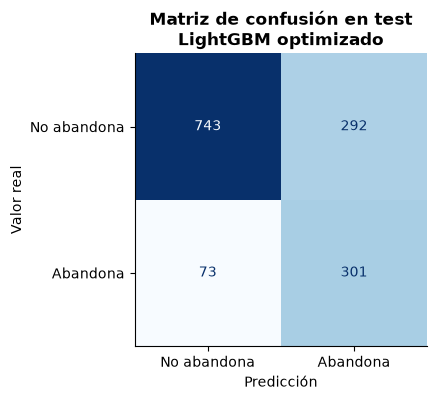

LightGBM optimizado


{'recall': 0.8048,
 'precision': 0.5076,
 'roc_auc': 0.8482,
 'pr_auc': 0.6668,
 'f1': 0.6225,
 'accuracy': 0.741}

In [5]:
from sklearn.linear_model import LogisticRegression
from lightgbm import LGBMClassifier
from sklearn.metrics import (recall_score, precision_score, roc_auc_score, average_precision_score,
                             f1_score, accuracy_score, confusion_matrix, ConfusionMatrixDisplay)
ruta_sel = RES / "03_seleccion.json"
SELECCION = json.loads(ruta_sel.read_text()) if ruta_sel.exists() else {'modelo': 'LightGBM optimizado', 'clase': 'LGBMClassifier', 'parametros': {'n_estimators': 600, 'learning_rate': 0.018928663564375343, 'num_leaves': 32, 'max_depth': 2, 'min_child_samples': 132, 'subsample': 0.630050532322413, 'colsample_bytree': 0.8722648734591396, 'reg_lambda': 4.478210759792659, 'reg_alpha': 0.28373105188382913, 'subsample_freq': 1, 'class_weight': 'balanced', 'random_state': 42, 'n_jobs': 1, 'verbose': -1}, 'umbral': 0.5, 'razon': 'El modelo optimizado gana en recall con p < 0,05.'}
CLASES = {"LogisticRegression": LogisticRegression, "LGBMClassifier": LGBMClassifier}
modelo_final = construir_pipeline(CLASES[SELECCION["clase"]](**SELECCION["parametros"])).fit(X_train, y_train)
UMBRAL = SELECCION["umbral"]
prob = modelo_final.predict_proba(X_test)[:, 1]
pred = (prob >= UMBRAL).astype(int)
mc = confusion_matrix(y_test, pred)
metricas_test = {"recall": recall_score(y_test, pred), "precision": precision_score(y_test, pred),
                 "roc_auc": roc_auc_score(y_test, prob), "pr_auc": average_precision_score(y_test, prob),
                 "f1": f1_score(y_test, pred), "accuracy": accuracy_score(y_test, pred)}
metricas_test = {k: round(float(v), 4) for k, v in metricas_test.items()}
fig, ax = plt.subplots(figsize=(4.4, 3.8))
ConfusionMatrixDisplay(mc, display_labels=["No abandona", "Abandona"]).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title(f"Matriz de confusión en test\n{SELECCION['modelo']}"); ax.set_xlabel("Predicción"); ax.set_ylabel("Valor real"); ax.grid(False)
guardar_figura(fig, "05_matriz_confusion_final.png"); plt.show()
print(SELECCION["modelo"]); metricas_test

## 2. Importancia por permutación (en el test)

Se desordena una variable a la vez y se mide cuánto cae el ROC-AUC en el test (10 repeticiones). Si al desordenarla el modelo empeora mucho, el modelo depende de ella.

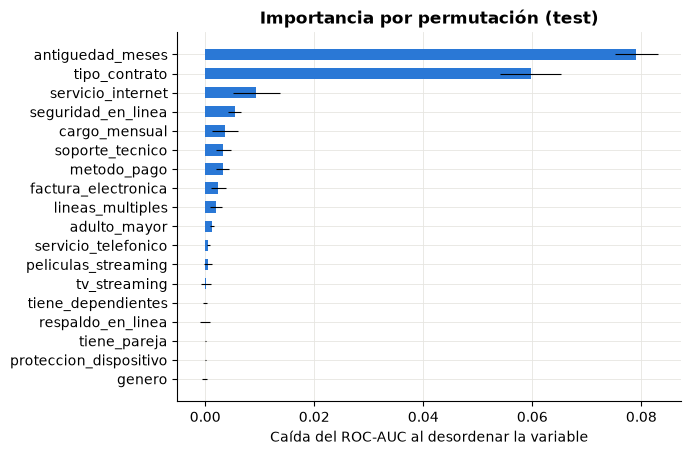

,variable,caida_roc_auc_media,desv
0,antiguedad_meses,0.0791,0.0040
15,tipo_contrato,0.0597,0.0056
8,servicio_internet,0.0094,0.0043
9,seguridad_en_linea,0.0054,0.0012
1,cargo_mensual,0.0037,0.0024
12,soporte_tecnico,0.0033,0.0014
17,metodo_pago,0.0032,0.0012
16,factura_electronica,0.0024,0.0014


In [6]:
from sklearn.inspection import permutation_importance
pi = permutation_importance(modelo_final, X_test, y_test, scoring="roc_auc", n_repeats=10, random_state=SEMILLA)
imp = (pd.DataFrame({"variable": X_test.columns, "caida_roc_auc_media": pi.importances_mean,
                     "desv": pi.importances_std}).sort_values("caida_roc_auc_media", ascending=False).round(4))
imp.to_csv(RES / "05_importancia_permutacion.csv", index=False)
fig, ax = plt.subplots(figsize=(6.5, 4.8))
t = imp.iloc[::-1]
ax.barh(t["variable"], t["caida_roc_auc_media"], xerr=t["desv"], color=AZUL, height=0.6, error_kw={"lw": 0.8})
ax.set_title("Importancia por permutación (test)"); ax.set_xlabel("Caída del ROC-AUC al desordenar la variable")
guardar_figura(fig, "05_importancia_permutacion.png"); plt.show()
imp.head(8)

**Lectura.** El modelo depende sobre todo de **la antigüedad** (desordenarla baja el ROC-AUC en 0.079) y del **tipo de contrato** (0.060). Muy por detrás vienen el servicio de internet (0.009), la seguridad en línea, el cargo mensual, el soporte técnico y el método de pago. **El género no aporta nada** (−0.0001), y la pareja, los dependientes y el respaldo en línea tampoco. Coincide con el EDA: las variables de "relación con la empresa" pesan mucho más que las demográficas.

## 3. SHAP: explicación global y de casos individuales

SHAP reparte la predicción de cada cliente entre sus variables: valores positivos empujan hacia "abandona" y negativos hacia "se queda". Se calcula sobre las variables ya transformadas por el Pipeline (cada categoría one-hot es una columna).

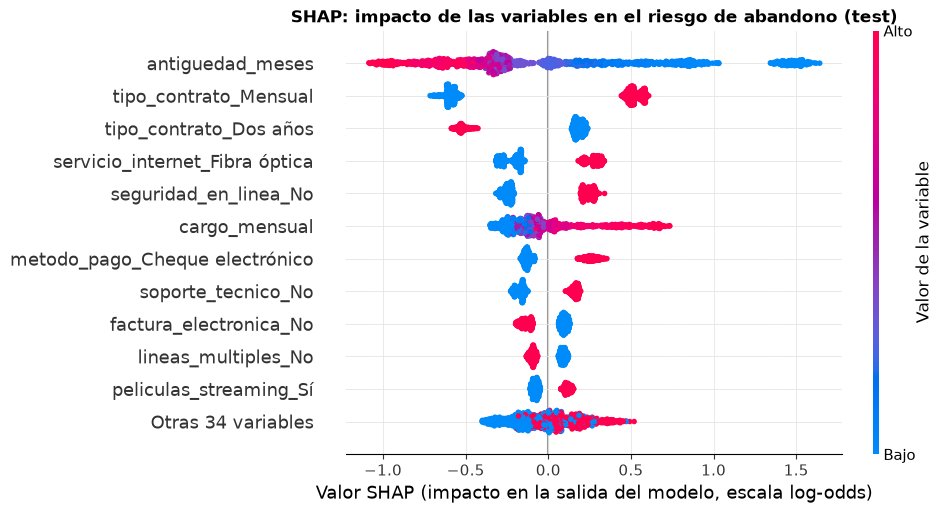

,variable_transformada,shap_abs_medio
0,antiguedad_meses,0.5597
37,tipo_contrato_Mensual,0.5543
36,tipo_contrato_Dos años,0.2652
16,servicio_internet_Fibra óptica,0.2474
18,seguridad_en_linea_No,0.2460
1,cargo_mensual,0.1994
41,metodo_pago_Cheque electrónico,0.1731
27,soporte_tecnico_No,0.1656
39,factura_electronica_No,0.1134
12,lineas_multiples_No,0.0932


In [7]:
import re
import shap

def traducir_ejes_shap(fig):
    """Pasa al español los textos fijos que SHAP dibuja en inglés."""
    for ax in fig.axes:
        etiquetas = [t.get_text() for t in ax.get_yticklabels()]
        if etiquetas == ["Low", "High"] or etiquetas == ["Bajo", "Alto"]:
            ax.set_yticks(ax.get_yticks()); ax.set_yticklabels(["Bajo", "Alto"])
        elif any("other features" in e for e in etiquetas):
            ax.set_yticks(ax.get_yticks())
            ax.set_yticklabels([re.sub(r"^(?:Sum of )?(\d+) other features$", r"Otras \1 variables", e)
                                for e in etiquetas])
prep_f, est_f = modelo_final.named_steps["prep"], modelo_final.named_steps["modelo"]
nombres = [n.split("__", 1)[1] for n in prep_f.get_feature_names_out()]
Z_train = pd.DataFrame(prep_f.transform(X_train), columns=nombres)
Z_test = pd.DataFrame(prep_f.transform(X_test), columns=nombres, index=X_test.index)
if SELECCION["clase"] == "LogisticRegression":
    explicador = shap.LinearExplainer(est_f, Z_train)
else:
    explicador = shap.TreeExplainer(est_f)
sv = explicador(Z_test)
if sv.values.ndim == 3:
    sv = sv[:, :, 1]
shap_imp = (pd.DataFrame({"variable_transformada": nombres, "shap_abs_medio": np.abs(sv.values).mean(0)})
            .sort_values("shap_abs_medio", ascending=False).round(4))
shap_imp.to_csv(RES / "05_shap_importancia.csv", index=False)
plt.figure()
shap.plots.beeswarm(sv, max_display=12, show=False, color_bar_label="Valor de la variable")
traducir_ejes_shap(plt.gcf())
plt.title("SHAP: impacto de las variables en el riesgo de abandono (test)")
plt.xlabel("Valor SHAP (impacto en la salida del modelo, escala log-odds)")
# Nota: los valores numéricos de las variables aparecen escalados (z) porque SHAP trabaja tras el Pipeline.
plt.gcf().set_size_inches(8, 5.5)
guardar_figura(plt.gcf(), "05_shap_resumen.png"); plt.show()
shap_imp.head(10)

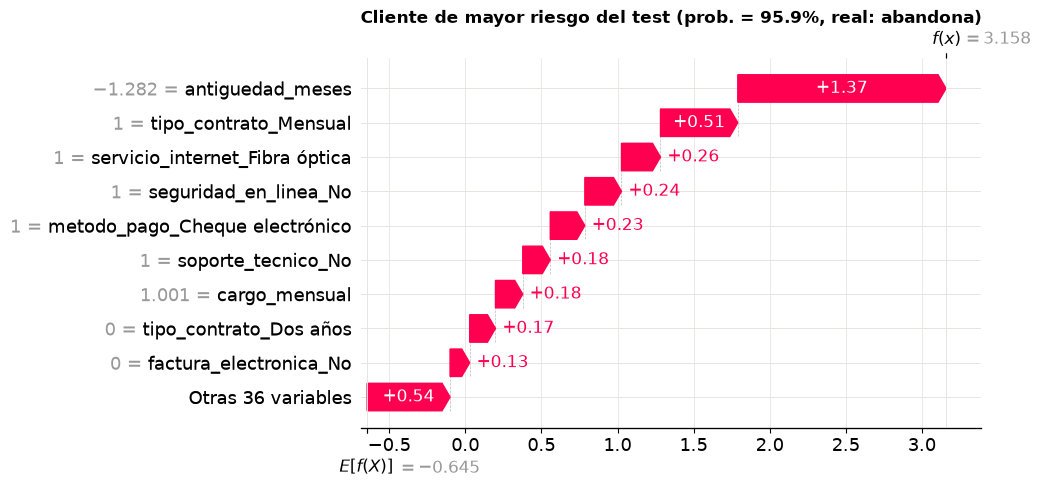

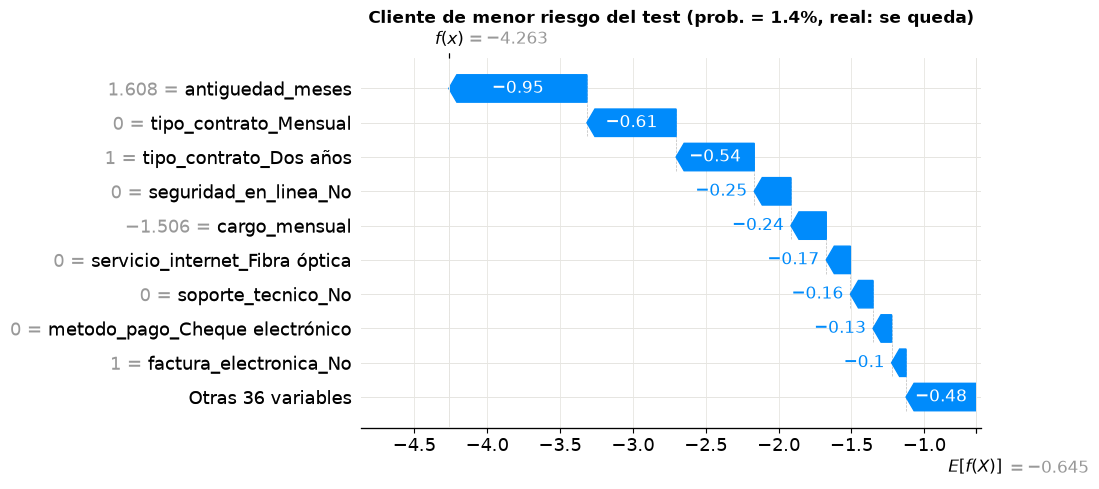

,0,1
caso,mayor riesgo,menor riesgo
probabilidad,0.9592,0.0139
abandono_real,1,0
antiguedad_meses,1,72
cargo_mensual,95.1,19.55
genero,Hombre,Mujer
adulto_mayor,Sí,No
tiene_pareja,Sí,Sí
tiene_dependientes,No,Sí
servicio_telefonico,Sí,Sí


In [8]:
pos_alto, pos_bajo = int(np.argmax(prob)), int(np.argmin(prob))
casos = []
for etiqueta, pos, archivo in [("mayor riesgo", pos_alto, "05_shap_caso_alto.png"), ("menor riesgo", pos_bajo, "05_shap_caso_bajo.png")]:
    plt.figure()
    shap.plots.waterfall(sv[pos], max_display=10, show=False)
    traducir_ejes_shap(plt.gcf())
    plt.title(f"Cliente de {etiqueta} del test (prob. = {prob[pos]:.1%}, real: {'abandona' if y_test.iloc[pos] else 'se queda'})")
    plt.gcf().set_size_inches(8, 4.8)
    guardar_figura(plt.gcf(), archivo); plt.show()
    fila = X_test.iloc[pos]
    casos.append({"caso": etiqueta, "probabilidad": round(float(prob[pos]), 4), "abandono_real": int(y_test.iloc[pos]),
                  **{k: (v.item() if hasattr(v, "item") else v) for k, v in fila.items()}})
guardar_json(casos, "05_casos_individuales.json")
pd.DataFrame(casos).T

**Lectura.**
- **Global:** las variables con mayor impacto medio son `antiguedad_meses` (antigüedad baja = mucho más riesgo), el **contrato mensual** (empuja hacia el abandono) frente al de dos años (lo reduce), la **fibra óptica**, la **falta de seguridad en línea**, un **cargo mensual alto**, el **cheque electrónico** y la **falta de soporte técnico**. La dirección de cada efecto coincide con los hallazgos del EDA, lo que da confianza en que el modelo aprendió patrones razonables.
- **Cliente de mayor riesgo (95.9 %, sí abandonó):** 1 mes de antigüedad, contrato mensual, fibra óptica sin seguridad ni soporte, cheque electrónico y cargo de 95.10 USD: todos los factores de riesgo a la vez; la antigüedad sola suma +1.37 en la escala log-odds.
- **Cliente de menor riesgo (1.4 %, no abandonó):** 72 meses de antigüedad, contrato de dos años, sin internet, pago por transferencia automática y cargo de 19.55 USD.
- Nota: en los gráficos de casos, los números junto a las variables numéricas están escalados (puntuación z) porque SHAP trabaja después del Pipeline.

## 4. Revisión de sesgo: recall y precisión por grupo

El modelo **no usa** la etiqueta para decidir a qué grupo pertenece un cliente, pero `genero` y `adulto_mayor` sí son variables de entrada. Revisamos si el modelo detecta peor (recall) o alerta en exceso (precisión) a algún grupo, usando el test.

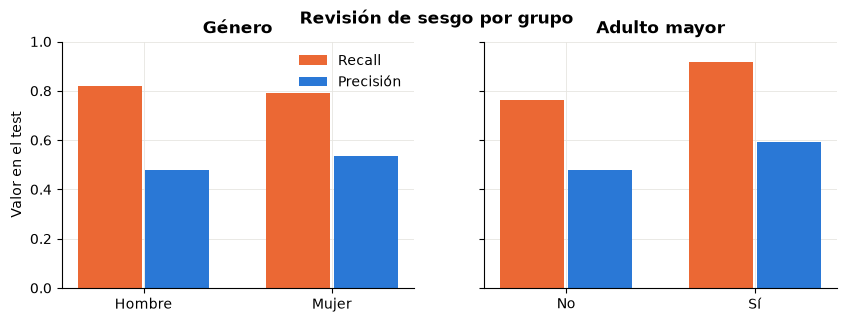

,variable,grupo,n,tasa_abandono_real,tasa_alertas,recall,precision
0,genero,Hombre,722,0.2507,0.4266,0.8177,0.4805
1,genero,Mujer,687,0.2809,0.4148,0.7927,0.5368
2,adulto_mayor,No,1187,0.2325,0.3715,0.7645,0.4785
3,adulto_mayor,Sí,222,0.4414,0.6847,0.9184,0.5921


,recall,precision,tasa_alertas
variable,,,
adulto_mayor,0.1539,0.1136,0.3132
genero,0.0250,0.0563,0.0118


In [9]:
filas = []
for v in ["genero", "adulto_mayor"]:
    for g in sorted(X_test[v].unique()):
        m = (X_test[v] == g).values
        filas.append({"variable": v, "grupo": g, "n": int(m.sum()), "tasa_abandono_real": y_test[m].mean(),
                      "tasa_alertas": pred[m].mean(), "recall": recall_score(y_test[m], pred[m]),
                      "precision": precision_score(y_test[m], pred[m])})
sesgo = pd.DataFrame(filas).round(4)
sesgo.to_csv(RES / "05_sesgo.csv", index=False)
brechas = sesgo.groupby("variable")[["recall", "precision", "tasa_alertas"]].agg(lambda s: s.max() - s.min()).round(4)
brechas.to_csv(RES / "05_brechas_sesgo.csv")
fig, axs = plt.subplots(1, 2, figsize=(10, 3.2), sharey=True)
for ax, v, titulo in zip(axs, ["genero", "adulto_mayor"], ["Género", "Adulto mayor"]):
    t = sesgo[sesgo.variable == v]; x = np.arange(len(t))
    ax.bar(x - 0.18, t["recall"], 0.34, color=NARANJA, label="Recall")
    ax.bar(x + 0.18, t["precision"], 0.34, color=AZUL, label="Precisión")
    ax.set_xticks(x); ax.set_xticklabels(t["grupo"]); ax.set_title(titulo); ax.set_ylim(0, 1)
axs[0].set_ylabel("Valor en el test"); axs[0].legend(frameon=False)
fig.suptitle("Revisión de sesgo por grupo", fontweight="bold")
guardar_figura(fig, "05_sesgo.png"); plt.show()
display(sesgo); brechas

**Lectura.**
- **Género:** brechas pequeñas (recall 0.818 hombres frente a 0.793 mujeres; precisión 0.481 frente a 0.537; ambos grupos reciben alertas en proporción casi igual, 42.7 % frente a 41.5 %). No vemos un sesgo relevante, y el género no influye en el modelo (importancia ≈ 0).
- **Adulto mayor:** brecha grande. El modelo alerta al **68.5 %** de los adultos mayores frente al 37.2 % del resto. Su recall es más alto (0.918 frente a 0.765), pero la mitad de ese efecto refleja que su tasa real de abandono también es mayor (44.1 % frente a 23.3 %). El grupo es pequeño en el test (222 personas), así que las cifras son inestables.
- **Qué se haría:** (1) usar las alertas solo para **ofrecer** beneficios, nunca para negar servicios o subir precios, de modo que una alerta de más no perjudique al cliente; (2) vigilar estas métricas por grupo cada vez que se reentrene; (3) si la brecha en tasa de alertas preocupa, probar umbrales por grupo o retirar `adulto_mayor` del modelo y medir cuánto recall se pierde.

## 5. Guardar el modelo final

Se guarda el **Pipeline completo** (preprocesamiento + modelo) en `app/modelo.joblib` y la ficha del modelo en `resultados/modelo_final.json`. El mismo modelo se puede regenerar con `python scripts/entrenar.py`.

In [10]:
import joblib, datetime, platform, sklearn, lightgbm
RUTA_APP = Path("../app") if EN_REPO else Path("app")
RUTA_APP.mkdir(exist_ok=True)
joblib.dump(modelo_final, RUTA_APP / "modelo.joblib")
ficha = {
    "modelo": SELECCION["modelo"], "clase": SELECCION["clase"], "parametros": SELECCION["parametros"],
    "umbral": UMBRAL, "metricas_test": metricas_test,
    "matriz_confusion_test": {"vn": int(mc[0, 0]), "fp": int(mc[0, 1]), "fn": int(mc[1, 0]), "vp": int(mc[1, 1])},
    "n_train": len(X_train), "n_test": len(X_test), "variables": VARIABLES_MODELO,
    "fecha": datetime.date.today().isoformat(),
    "versiones": {"python": platform.python_version(), "scikit-learn": sklearn.__version__,
                  "lightgbm": lightgbm.__version__, "pandas": pd.__version__, "numpy": np.__version__},
}
guardar_json(ficha, "modelo_final.json")
cargado = joblib.load(RUTA_APP / "modelo.joblib")
assert np.allclose(cargado.predict_proba(X_test)[:, 1], prob)
print("Modelo guardado y verificado:", RUTA_APP / "modelo.joblib")
ficha

Modelo guardado y verificado: ../app/modelo.joblib


{'modelo': 'LightGBM optimizado',
 'clase': 'LGBMClassifier',
 'parametros': {'n_estimators': 600,
  'learning_rate': 0.018928663564375343,
  'num_leaves': 32,
  'max_depth': 2,
  'min_child_samples': 132,
  'subsample': 0.630050532322413,
  'colsample_bytree': 0.8722648734591396,
  'reg_lambda': 4.478210759792659,
  'reg_alpha': 0.28373105188382913,
  'subsample_freq': 1,
  'class_weight': 'balanced',
  'random_state': 42,
  'n_jobs': 1,
  'verbose': -1},
 'umbral': 0.5,
 'metricas_test': {'recall': 0.8048,
  'precision': 0.5076,
  'roc_auc': 0.8482,
  'pr_auc': 0.6668,
  'f1': 0.6225,
  'accuracy': 0.741},
 'matriz_confusion_test': {'vn': 743, 'fp': 292, 'fn': 73, 'vp': 301},
 'n_train': 5634,
 'n_test': 1409,
 'variables': ['antiguedad_meses',
  'cargo_mensual',
  'genero',
  'adulto_mayor',
  'tiene_pareja',
  'tiene_dependientes',
  'servicio_telefonico',
  'lineas_multiples',
  'servicio_internet',
  'seguridad_en_linea',
  'respaldo_en_linea',
  'proteccion_dispositivo',
  'sopo

## Conclusiones

1. **Modelo final: LightGBM optimizado** (Pipeline completo, umbral 0.5). En el test: **recall 0.805** (301 de 374 clientes que abandonan detectados), precisión 0.508, ROC-AUC 0.848 y PR-AUC 0.667.
2. El modelo se apoya sobre todo en **la antigüedad y el tipo de contrato**, seguidos del servicio de internet, los servicios de protección, el cargo mensual y el método de pago; el género no influye.
3. **Sesgo:** no hay brechas relevantes por género; sí hay más alertas para adultos mayores, en parte porque abandonan más. Se recomienda usar el modelo solo para ofrecer retención y monitorear por grupo.
4. El modelo queda guardado en `app/modelo.joblib` y se puede reproducir con `python scripts/entrenar.py`.